In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("All import done")

All import done


In [79]:
sns.set_theme(style="whitegrid")
print("Set theme done")
plt.rcParams['figure.figsize'] = (8,5)
print("Figure size: width:8, height:5 done")

Set theme done
Figure size: width:8, height:5 done


In [80]:
df=pd.read_csv("student-por.csv", sep=',')
print(df)

    school sex  age address famsize Pstatus  Medu  Fedu      Mjob      Fjob  \
0       GP   F   18       U     GT3       A     4     4   at_home   teacher   
1       GP   F   17       U     GT3       T     1     1   at_home     other   
2       GP   F   15       U     LE3       T     1     1   at_home     other   
3       GP   F   15       U     GT3       T     4     2    health  services   
4       GP   F   16       U     GT3       T     3     3     other     other   
..     ...  ..  ...     ...     ...     ...   ...   ...       ...       ...   
644     MS   F   19       R     GT3       T     2     3  services     other   
645     MS   F   18       U     LE3       T     3     1   teacher  services   
646     MS   F   18       U     GT3       T     1     1     other     other   
647     MS   M   17       U     LE3       T     3     1  services  services   
648     MS   M   18       R     LE3       T     3     2  services     other   

     ... famrel freetime  goout  Dalc  Walc health 

In [81]:
selected_features = ['age','studytime', 'failures', 'absences', 'schoolsup', 'famsup', 'Medu', 'Fedu',
'internet', 'higher', 'goout', 'health','traveltime', 'freetime']
print("Done")

Done


In [82]:
df['Pass'] = (df['G3'] >= 10).astype(int)
print("Done")

Done


In [83]:
X=df[selected_features].copy()
y=df['Pass']
print(X)

     age  studytime  failures  absences schoolsup famsup  Medu  Fedu internet  \
0     18          2         0         4       yes     no     4     4       no   
1     17          2         0         2        no    yes     1     1      yes   
2     15          2         0         6       yes     no     1     1      yes   
3     15          3         0         0        no    yes     4     2      yes   
4     16          2         0         0        no    yes     3     3       no   
..   ...        ...       ...       ...       ...    ...   ...   ...      ...   
644   19          3         1         4        no     no     2     3      yes   
645   18          2         0         4        no    yes     3     1      yes   
646   18          2         0         6        no     no     1     1       no   
647   17          1         0         6        no     no     3     1      yes   
648   18          1         0         4        no     no     3     2      yes   

    higher  goout  health  

In [84]:
#X-shape is (total sample,selected_features)'
print("Initial X Shape:", X.shape)
print("Target Distribution:\n", y.value_counts(normalize=True))

Initial X Shape: (649, 14)
Target Distribution:
 Pass
1    0.845917
0    0.154083
Name: proportion, dtype: float64


In [85]:
print("\nMissing values in selected features:\n", X.isnull().sum())
print("Duplicate rows across features:", X.duplicated().sum())


Missing values in selected features:
 age           0
studytime     0
failures      0
absences      0
schoolsup     0
famsup        0
Medu          0
Fedu          0
internet      0
higher        0
goout         0
health        0
traveltime    0
freetime      0
dtype: int64
Duplicate rows across features: 0


C:\Users\FR\AppData\Local\Temp\ipykernel_6308\3478420960.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Pass', data=df, palette='pastel')


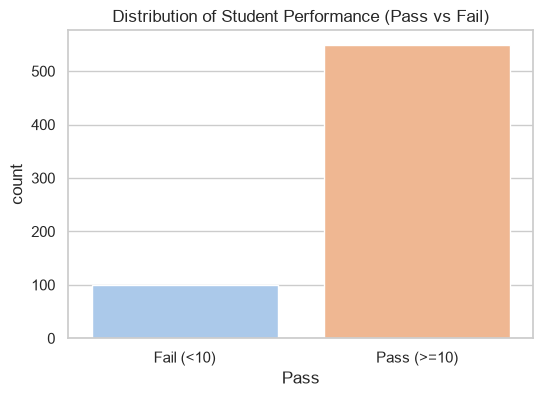

In [86]:
#EDA
plt.figure(figsize=(6, 4))
sns.countplot(x='Pass', data=df, palette='pastel')
plt.title('Distribution of Student Performance (Pass vs Fail)')
plt.xticks([0, 1], ['Fail (<10)', 'Pass (>=10)'])
plt.show()

In [87]:
numeric_cols = [
    'age', 'studytime', 'failures', 'absences', 
    'Medu', 'Fedu', 'goout', 'health', 
    'traveltime', 'freetime'
]
print("Done")

Done


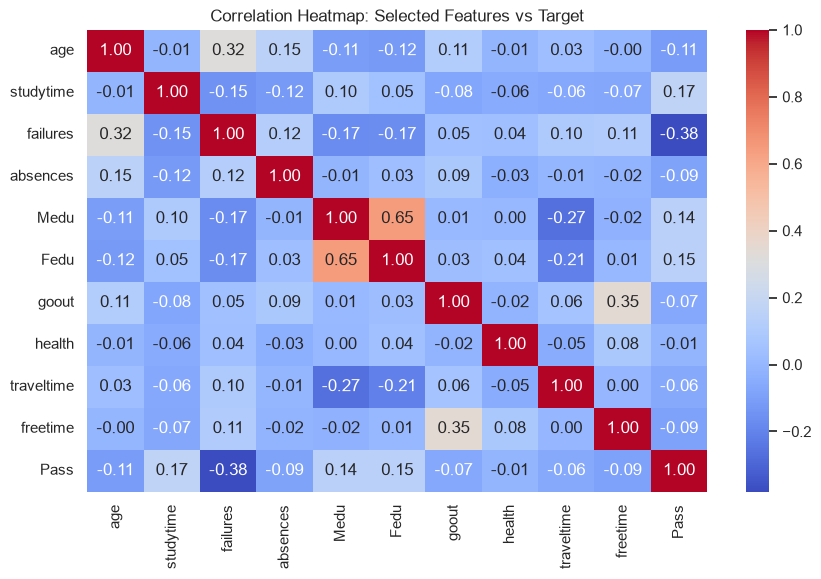

In [88]:
plt.figure(figsize=(10, 6))
sns.heatmap(df[numeric_cols + ['Pass']].corr(), annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title('Correlation Heatmap: Selected Features vs Target')
plt.show()

In [89]:
# 5. Data Encoding
# Map binary categorical columns from ('yes'/'no') to (1/0)
binary_map = {'yes': 1, 'no': 0}
categorical_cols = ['schoolsup', 'famsup', 'internet', 'higher']

for col in categorical_cols:
    X[col] = X[col].map(binary_map)

In [90]:
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [91]:
from sklearn.preprocessing import StandardScaler
print("Import")

Import


In [92]:
print("Final Processed Feature Matrix (X):")
X.info()
display(X.head(3))

Final Processed Feature Matrix (X):
<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   age         649 non-null    int64
 1   studytime   649 non-null    int64
 2   failures    649 non-null    int64
 3   absences    649 non-null    int64
 4   schoolsup   649 non-null    int64
 5   famsup      649 non-null    int64
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   internet    649 non-null    int64
 9   higher      649 non-null    int64
 10  goout       649 non-null    int64
 11  health      649 non-null    int64
 12  traveltime  649 non-null    int64
 13  freetime    649 non-null    int64
dtypes: int64(14)
memory usage: 71.1 KB


,age,studytime,failures,absences,schoolsup,famsup,Medu,Fedu,internet,higher,goout,health,traveltime,freetime
0,18,2,0,4,1,0,4,4,0,1,4,3,2,3
1,17,2,0,2,0,1,1,1,1,1,3,3,1,3
2,15,2,0,6,1,0,1,1,1,1,2,3,1,3


In [93]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (519, 14) Test: (130, 14)


In [94]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

log_reg = make_pipeline(StandardScaler(),
                        LogisticRegression(max_iter=1000, class_weight='balanced'))
dt = DecisionTreeClassifier(random_state=42, class_weight='balanced')
rf = RandomForestClassifier(random_state=42, class_weight='balanced')

log_reg.fit(X_train, y_train)
dt.fit(X_train, y_train)
rf.fit(X_train, y_train)
print("Baseline models trained.")

Baseline models trained.


In [95]:
from sklearn.model_selection import GridSearchCV

lr_grid = GridSearchCV(
    log_reg,
    {"logisticregression__C": [0.01, 0.1, 1, 10, 100]},
    cv=5, scoring="f1")
lr_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'logisticregression__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during 

In [96]:
dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42, class_weight='balanced'),
    {"max_depth": [3, 5, 7, 10, None],
     "min_samples_split": [2, 5, 10],
     "min_samples_leaf": [1, 2, 4]},
    cv=5, scoring="f1")
dt_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Con

In [97]:
# This may take a minute or two
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42, class_weight='balanced'),
    {"n_estimators": [100, 200, 300],
     "max_depth": [5, 10, None],
     "min_samples_split": [2, 5, 10]},
    cv=5, scoring="f1", n_jobs=-1)
rf_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [5, 10, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Cont

In [98]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest"],
    "Best CV F1": [lr_grid.best_score_, dt_grid.best_score_, rf_grid.best_score_],
    "Best Parameters": [lr_grid.best_params_, dt_grid.best_params_, rf_grid.best_params_],
})
results["Best CV F1"] = results["Best CV F1"].round(3)
pd.set_option("display.max_colwidth", None)
results

,Model,Best CV F1,Best Parameters
0,Logistic Regression,0.883,{'logisticregression__C': 0.01}
1,Decision Tree,0.888,"{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}"
2,Random Forest,0.912,"{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}"


In [99]:
import joblib

joblib.dump(lr_grid.best_estimator_, "best_logreg.pkl")
joblib.dump(dt_grid.best_estimator_, "best_tree.pkl")
joblib.dump(rf_grid.best_estimator_, "best_rf.pkl")
joblib.dump((X_train, X_test, y_train, y_test), "split_data.pkl")
print("Saved: best_logreg.pkl, best_tree.pkl, best_rf.pkl, split_data.pkl")

Saved: best_logreg.pkl, best_tree.pkl, best_rf.pkl, split_data.pkl


In [100]:
models = {
    "Logistic Regression": joblib.load("best_logreg.pkl"),
    "Decision Tree": joblib.load("best_tree.pkl"),
    "Random Forest": joblib.load("best_rf.pkl"),
}
X_train, X_test, y_train, y_test = joblib.load("split_data.pkl")
print("Test size:", X_test.shape)
print(y_test.value_counts())

Test size: (130, 14)
Pass
1    110
0     20
Name: count, dtype: int64


In [101]:
preds = {name: m.predict(X_test) for name, m in models.items()}
probs = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}
train_preds = {name: m.predict(X_train) for name, m in models.items()}
print("done")

done


In [102]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    balanced_accuracy_score
)

In [103]:
from sklearn.metrics import balanced_accuracy_score
rows = []
for name in models:
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds[name]),
        "Precision": precision_score(y_test, preds[name]),
        "Recall": recall_score(y_test, preds[name]),
        "F1-score": f1_score(y_test, preds[name]),
        "ROC-AUC": roc_auc_score(y_test, probs[name]),
        "Fail recall": recall_score(y_test, preds[name], pos_label=0),
        "Balanced acc": balanced_accuracy_score(y_test, preds[name]),
        "Train F1": f1_score(y_train, train_preds[name]),
    })
metrics = pd.DataFrame(rows).set_index("Model").round(3)
metrics["F1 gap (train - test)"] = (metrics["Train F1"] - metrics["F1-score"]).round(3)

# baseline: always predict "Pass"
print("Baseline accuracy (predict everyone Pass):", round(y_test.mean(), 3))
metrics

Baseline accuracy (predict everyone Pass): 0.846


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Fail recall,Balanced acc,Train F1,F1 gap (train - test)
Model,,,,,,,,,
Logistic Regression,0.738,0.880,0.800,0.838,0.557,0.4,0.600,0.892,0.054
Decision Tree,0.715,0.848,0.809,0.828,0.505,0.2,0.505,1.000,0.172
Random Forest,0.746,0.867,0.827,0.847,0.580,0.3,0.564,1.000,0.153


In [104]:
for name in models:
    print("=" * 50)
    print(name)
    print(classification_report(y_test, preds[name], target_names=["Fail", "Pass"]))

Logistic Regression
              precision    recall  f1-score   support

        Fail       0.27      0.40      0.32        20
        Pass       0.88      0.80      0.84       110

    accuracy                           0.74       130
   macro avg       0.57      0.60      0.58       130
weighted avg       0.79      0.74      0.76       130

Decision Tree
              precision    recall  f1-score   support

        Fail       0.16      0.20      0.18        20
        Pass       0.85      0.81      0.83       110

    accuracy                           0.72       130
   macro avg       0.50      0.50      0.50       130
weighted avg       0.74      0.72      0.73       130

Random Forest
              precision    recall  f1-score   support

        Fail       0.24      0.30      0.27        20
        Pass       0.87      0.83      0.85       110

    accuracy                           0.75       130
   macro avg       0.55      0.56      0.56       130
weighted avg       0.77   

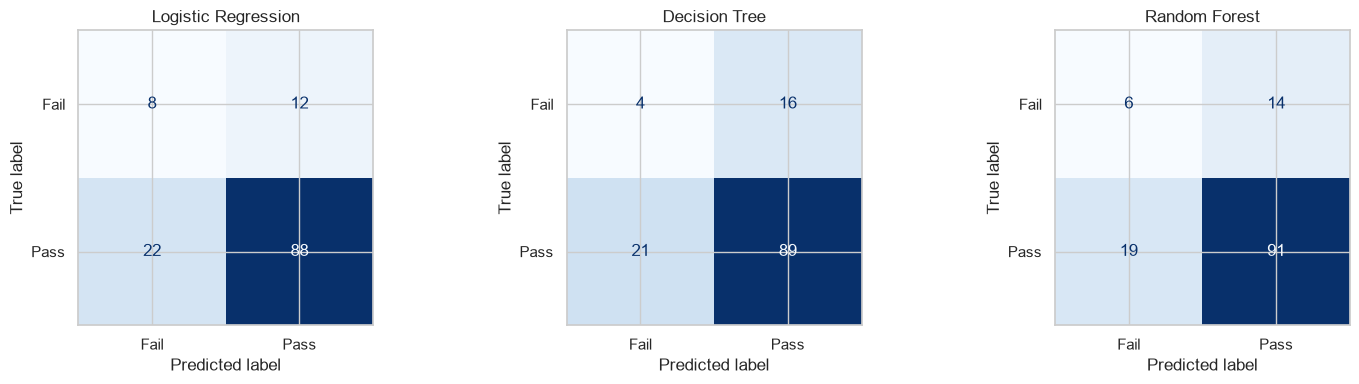

Logistic Regression: TN=8  FP=12  FN=22  TP=88
Decision Tree: TN=4  FP=16  FN=21  TP=89
Random Forest: TN=6  FP=14  FN=19  TP=91


In [105]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, preds[name])
    ConfusionMatrixDisplay(cm, display_labels=["Fail", "Pass"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

for name in models:
    tn, fp, fn, tp = confusion_matrix(y_test, preds[name]).ravel()
    print(f"{name}: TN={tn}  FP={fp}  FN={fn}  TP={tp}")

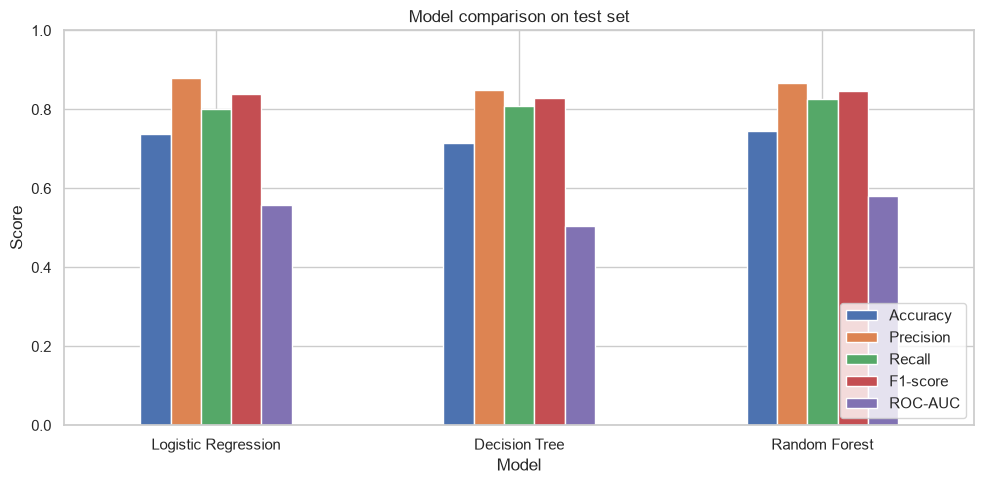

In [106]:
ax = metrics[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]].plot(
    kind="bar", figsize=(10, 5), rot=0)
ax.set_ylim(0, 1)
ax.set_title("Model comparison on test set")
ax.set_ylabel("Score")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

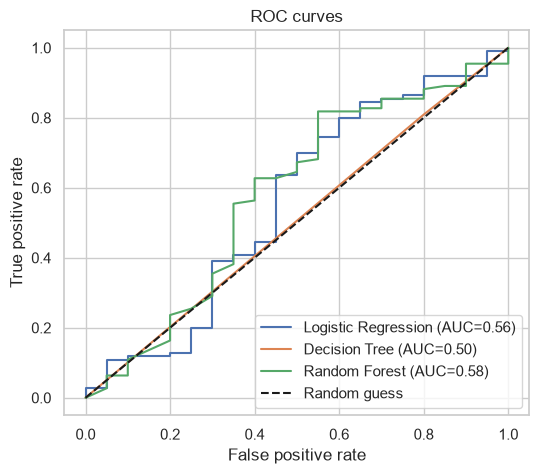

In [107]:
from sklearn.metrics import roc_curve
plt.figure(figsize=(6, 5))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, probs[name]):.2f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves"); plt.legend()
plt.show()

In [108]:
best_name = metrics["F1-score"].idxmax()
print("Best model by test F1:", best_name)
print(metrics.loc[best_name])

Best model by test F1: Random Forest
Accuracy                 0.746
Precision                0.867
Recall                   0.827
F1-score                 0.847
ROC-AUC                  0.580
Fail recall              0.300
Balanced acc             0.564
Train F1                 1.000
F1 gap (train - test)    0.153
Name: Random Forest, dtype: float64


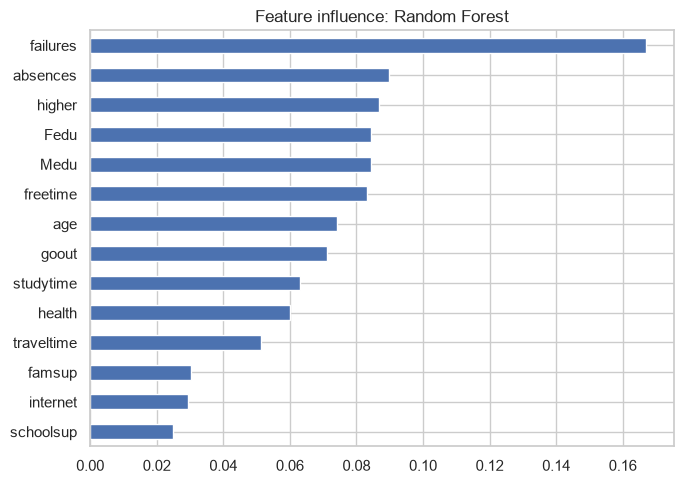

In [109]:
# Which features matter most? (for the best model, if it supports it)
best = models[best_name]
est = best[-1] if hasattr(best, "steps") else best
if hasattr(est, "feature_importances_"):
    imp = pd.Series(est.feature_importances_, index=X_test.columns).sort_values()
elif hasattr(est, "coef_"):
    imp = pd.Series(est.coef_[0], index=X_test.columns).sort_values()
imp.plot(kind="barh", figsize=(7, 5), title=f"Feature influence: {best_name}")
plt.tight_layout()
plt.show()

In [110]:
import pandas as pd

def predict_student():
    print("=== STUDENT PERFORMANCE PREDICTION ===")

    age = int(input("Age (15-22): "))
    studytime = int(input("Study time (1-4): "))
    failures = int(input("Previous failures (0-3): "))
    absences = int(input("Number of absences: "))

    schoolsup = input("Extra school support? (yes/no): ").lower()
    famsup = input("Family educational support? (yes/no): ")

    medu = int(input("Mother's education (0-4): "))
    fedu = int(input("Father's education (0-4): "))

    internet = input("Internet access? (yes/no): ").lower()
    higher = input("Wants higher education? (yes/no): ").lower()

    goout = int(input("Going out with friends (1-5): "))
    health = int(input("Health status (1-5): "))
    traveltime = int(input("Travel time (1-4): "))
    freetime = int(input("Free time after school (1-5): "))

    student = pd.DataFrame([{
        "age": age,
        "studytime": studytime,
        "failures": failures,
        "absences": absences,
        "schoolsup": 1 if schoolsup == "yes" else 0,
        "famsup": 1 if famsup.lower() == "yes" else 0,
        "Medu": medu,
        "Fedu": fedu,
        "internet": 1 if internet == "yes" else 0,
        "higher": 1 if higher == "yes" else 0,
        "goout": goout,
        "health": health,
        "traveltime": traveltime,
        "freetime": freetime
    }])

    # Use the trained Random Forest model
    model = models["Random Forest"]

    prediction = model.predict(student)[0]

    probability = model.predict_proba(student)[0]
    class_index = list(model.classes_).index(prediction)
    confidence = probability[class_index] * 100

    result = "PASS" if prediction == 1 else "FAIL"

    print("\n========== PREDICTION RESULT ==========")
    print("Student Result:", result)
    print(f"Model Confidence: {confidence:.2f}%")
    print("=======================================")

predict_student()

=== STUDENT PERFORMANCE PREDICTION ===


Age (15-22):  22
Study time (1-4):  4
Previous failures (0-3):  0
Number of absences:  0
Extra school support? (yes/no):  yes
Family educational support? (yes/no):  yes
Mother's education (0-4):  3
Father's education (0-4):  3
Internet access? (yes/no):  yes
Wants higher education? (yes/no):  yes
Going out with friends (1-5):  2
Health status (1-5):  5
Travel time (1-4):  4
Free time after school (1-5):  5



========== PREDICTION RESULT ==========
Student Result: PASS
Model Confidence: 86.50%
